# Season Lengths from NEX-GDDP-CMIP6 models: spatial trends

In [1]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.fft import fft

import matplotlib.ticker as mticker
from matplotlib.ticker import AutoMinorLocator, MultipleLocator
from cartopy import crs as ccrs, feature as cfeature
import netCDF4
from netCDF4 import Dataset
from datetime import datetime as dt

import scipy.stats as stats
from sklearn import linear_model
import statsmodels.api as sm
import seaborn as sns

import pymannkendall as mk

# to get rid of runtime warnings when OLS fits hit a divide by zero - handled by setting R2 and p-vals appropriately
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

# latitude & longitude ranges for NH and SH midlatitudes so they will be easy to adjust
nh_min = 23.5
nh_max = 70
sh_min = -60
sh_max = -23.5

In [2]:
# run once per session
#! pip install pymannkendall

## Load in ERA5 Season length data

In [2]:
%%time
# read era5 seasons in
input_path = '../../../../Data/ERA5-global/Analysis/New-Fourier/Seasons/1961-2025_ALL_season_stats.nc'
ds_era5 = xr.open_dataset(input_path)
ds_era5.load()


CPU times: user 58 ms, sys: 976 ms, total: 1.03 s
Wall time: 1.76 s


<xarray.Dataset> Size: 4GB
Dimensions:       (time: 65, lat: 721, lon: 1440)
Coordinates:
  * time          (time) datetime64[ns] 520B 1961-01-01 ... 2025-01-01
  * lat           (lat) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * lon           (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    WinterStart   (time, lat, lon) float64 540MB 88.0 88.0 88.0 ... 219.0 219.0
    WinterEnd     (time, lat, lon) float64 540MB 125.0 125.0 ... 219.0 219.0
    WinterLength  (time, lat, lon) float64 540MB 38.0 38.0 38.0 ... 0.0 0.0 0.0
    SummerStart   (time, lat, lon) float64 540MB 135.0 135.0 ... 150.0 150.0
    SummerEnd     (time, lat, lon) float64 540MB 224.0 224.0 ... 252.0 252.0
    SummerLength  (time, lat, lon) float64 540MB 90.0 90.0 90.0 ... 103.0 103.0
    SpringLength  (time, lat, lon) float64 540MB 193.0 193.0 ... 137.0 137.0
    AutumnLength  (time, lat, lon) float64 540MB 0.0 0.0 0.0 ... 150.0 150.0
    lsm           (lat, lon) float64 8MB 1.0 1.0 1.0 1.0 1.0 ... 0.0 0.0 0.0 0.0

### Restrict to land only, reduced area, and drop start/end variables

In [3]:
ds_era5 = ds_era5.drop_vars(['WinterStart','WinterEnd','SummerStart','SummerEnd']).where(ds_era5.lsm > 0.5)

In [4]:
#ds_era5.sel(time='1961').WinterLength.plot()
ds_era5 = ds_era5.drop_vars('lsm')
ds_era5 = ds_era5.sel(lat=slice(sh_min,nh_max))
ds_era5

<xarray.Dataset> Size: 2GB
Dimensions:       (time: 65, lat: 521, lon: 1440)
Coordinates:
  * time          (time) datetime64[ns] 520B 1961-01-01 ... 2025-01-01
  * lat           (lat) float64 4kB -60.0 -59.75 -59.5 ... 69.5 69.75 70.0
  * lon           (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    WinterLength  (time, lat, lon) float64 390MB nan nan nan nan ... nan nan nan
    SummerLength  (time, lat, lon) float64 390MB nan nan nan nan ... nan nan nan
    SpringLength  (time, lat, lon) float64 390MB nan nan nan nan ... nan nan nan
    AutumnLength  (time, lat, lon) float64 390MB nan nan nan nan ... nan nan nan

# Analyze ERA5 Season Length trends over 1990-2025

In [5]:
# restrict to 1990-2025
ds_era5 = ds_era5.sel(time=slice('1990','2025'))
ds_era5
                                    

<xarray.Dataset> Size: 864MB
Dimensions:       (time: 36, lat: 521, lon: 1440)
Coordinates:
  * time          (time) datetime64[ns] 288B 1990-01-01 ... 2025-01-01
  * lat           (lat) float64 4kB -60.0 -59.75 -59.5 ... 69.5 69.75 70.0
  * lon           (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    WinterLength  (time, lat, lon) float64 216MB nan nan nan nan ... nan nan nan
    SummerLength  (time, lat, lon) float64 216MB nan nan nan nan ... nan nan nan
    SpringLength  (time, lat, lon) float64 216MB nan nan nan nan ... nan nan nan
    AutumnLength  (time, lat, lon) float64 216MB nan nan nan nan ... nan nan nan

### Linear trends in season lengths for each grid cell 1990-2025

In [6]:
%%time

# takes XX min for 36 years

# grid parameters for looping
num_lat = ds_era5.lat.shape[0]
num_lon = ds_era5.lon.shape[0]
loop_lats = ds_era5.lat.values[:num_lat]
loop_lons = ds_era5.lon.values[:num_lon]


# variables for OLS results, p-val needed for FDR adjustment
summerlength_slope = xr.DataArray(np.zeros((num_lat,num_lon)), 
                            coords=[loop_lats, loop_lons], 
                            dims=['lat','lon'])
summerlength_pval = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])
winterlength_slope = xr.DataArray(np.zeros((num_lat,num_lon)), 
                            coords=[loop_lats, loop_lons], 
                            dims=['lat','lon'])
winterlength_pval = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])
springlength_slope = xr.DataArray(np.zeros((num_lat,num_lon)), 
                            coords=[loop_lats, loop_lons], 
                            dims=['lat','lon'])
springlength_pval = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])
autumnlength_slope = xr.DataArray(np.zeros((num_lat,num_lon)), 
                            coords=[loop_lats, loop_lons], 
                            dims=['lat','lon'])
autumnlength_pval = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])

# add attributes for each season fit
summerlength_slope.attrs["long_name"] = "Slope of linear fit of Summer length over time"
summerlength_slope.attrs["units"] = "Days/year"

summerlength_pval.attrs["long_name"] = "p-value of linear fit"
summerlength_pval.attrs["units"] = "None"

winterlength_slope.attrs["long_name"] = "Slope of linear fit of Winter length over time"
winterlength_slope.attrs["units"] = "Days/year"

winterlength_pval.attrs["long_name"] = "p-value of linear fit"
winterlength_pval.attrs["units"] = "None"

springlength_slope.attrs["long_name"] = "Slope of linear fit of Spring length over time"
springlength_slope.attrs["units"] = "Days/year"

springlength_pval.attrs["long_name"] = "p-value of linear fit"
springlength_pval.attrs["units"] = "None"

autumnlength_slope.attrs["long_name"] = "Slope of linear fit of Autumn length over time"
autumnlength_slope.attrs["units"] = "Days/year"

autumnlength_pval.attrs["long_name"] = "p-value of linear fit"
autumnlength_pval.attrs["units"] = "None"


# loop through all of the lat,lon of interest
for input_lat in loop_lats:
    for input_lon in loop_lons:

        # if first summer length is nan this cell is not on land and/or outside lat range of data so skip it and set slopes to nan and pvals to 0.999
        if(np.isnan(ds_era5.SummerLength.sel(lat=input_lat, lon=input_lon).values[0])):
            summerlength_slope.loc[input_lat, input_lon], winterlength_slope.loc[input_lat, input_lon], springlength_slope.loc[input_lat, input_lon], autumnlength_slope.loc[input_lat, input_lon] = np.nan, np.nan, np.nan, np.nan 
            summerlength_pval.loc[input_lat, input_lon], winterlength_pval.loc[input_lat, input_lon], springlength_pval.loc[input_lat, input_lon], autumnlength_pval.loc[input_lat, input_lon] = 0.999, 0.999, 0.999, 0.999

        else:
            # *** SUMMER ***
            # create x & y values for linear fit
            x = ds_era5.time.dt.year.values
            y = ds_era5.SummerLength.sel(lat=input_lat, lon=input_lon).values
    
            # OLS fit 
            x = sm.add_constant(x)
            model = sm.OLS(y, x).fit()
    
            # load up data arrays with fit values
            summerlength_slope.loc[input_lat, input_lon] = model.params[1]
            
            # deal with any grid cells that return nan or zero for Pvalue because FDR function requires between 0 and 1
            if np.isnan(model.pvalues[1]):
                summerlength_pval.loc[input_lat, input_lon] = 0.999
            elif (model.pvalues[1] == 0):
                summerlength_pval.loc[input_lat, input_lon] = 1e-10
            else:
                # otherwise fit pvalue is OK
                summerlength_pval.loc[input_lat, input_lon] = model.pvalues[1]

            # *** WINTER ***
            # create x & y values
            x = ds_era5.time.dt.year.values
            y = ds_era5.WinterLength.sel(lat=input_lat, lon=input_lon).values
    
            # OLS fit 
            x = sm.add_constant(x)
            model = sm.OLS(y, x).fit()
    
            # load up data arrays with fit values
            winterlength_slope.loc[input_lat, input_lon] = model.params[1]
            
            # deal with few grid cells that return nan or zero for Pvalue because FDR function needs between 0 and 1
            if np.isnan(model.pvalues[1]):
                winterlength_pval.loc[input_lat, input_lon] = 0.999
            elif (model.pvalues[1] == 0):
                winterlength_pval.loc[input_lat, input_lon] = 1e-10
            else:
                # otherwise fit pvalue is OK
                winterlength_pval.loc[input_lat, input_lon] = model.pvalues[1]

            # *** SPRING ***
            # create x & y values
            x = ds_era5.time.dt.year.values
            y = ds_era5.SpringLength.sel(lat=input_lat, lon=input_lon).values
    
            # OLS fit 
            x = sm.add_constant(x)
            model = sm.OLS(y, x).fit()
    
            # load up data arrays with fit values
            springlength_slope.loc[input_lat, input_lon] = model.params[1]
            
            # deal with few grid cells that return nan or zero for Pvalue because FDR function needs between 0 and 1
            if np.isnan(model.pvalues[1]):
                springlength_pval.loc[input_lat, input_lon] = 0.999
            elif (model.pvalues[1] == 0):
                springlength_pval.loc[input_lat, input_lon] = 1e-10
            else:
                # otherwise fit pvalue is OK
                springlength_pval.loc[input_lat, input_lon] = model.pvalues[1]

            # *** AUTUMN ***
            # create x & y values
            x = ds_era5.time.dt.year.values
            y = ds_era5.AutumnLength.sel(lat=input_lat, lon=input_lon).values
    
            # OLS fit 
            x = sm.add_constant(x)
            model = sm.OLS(y, x).fit()
    
            # load up data arrays with fit values
            autumnlength_slope.loc[input_lat, input_lon] = model.params[1]
            
            # deal with few grid cells that return nan or zero for Pvalue because FDR function needs between 0 and 1
            if np.isnan(model.pvalues[1]):
                autumnlength_pval.loc[input_lat, input_lon] = 0.999
            elif (model.pvalues[1] == 0):
                autumnlength_pval.loc[input_lat, input_lon] = 1e-10
            else:
                # otherwise fit pvalue is OK
                autumnlength_pval.loc[input_lat, input_lon] = model.pvalues[1]

# results dataset
results_ds = xr.Dataset(data_vars={'SummerLengthSlope':summerlength_slope,
                                   'SummerLengthP':summerlength_pval,
                                   'WinterLengthSlope':winterlength_slope,
                                   'WinterLengthP':winterlength_pval,
                                   'SpringLengthSlope':springlength_slope,
                                   'SpringLengthP':springlength_pval,
                                   'AutumnLengthSlope':autumnlength_slope,
                                   'AutumnLengthP':autumnlength_pval
                                  })

# see results
results_ds

CPU times: user 11min 9s, sys: 3.77 s, total: 11min 13s
Wall time: 11min 14s


<xarray.Dataset> Size: 48MB
Dimensions:            (lat: 521, lon: 1440)
Coordinates:
  * lat                (lat) float64 4kB -60.0 -59.75 -59.5 ... 69.5 69.75 70.0
  * lon                (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.5 179.8
Data variables:
    SummerLengthSlope  (lat, lon) float64 6MB nan nan nan nan ... nan nan nan
    SummerLengthP      (lat, lon) float64 6MB 0.999 0.999 0.999 ... 0.999 0.999
    WinterLengthSlope  (lat, lon) float64 6MB nan nan nan nan ... nan nan nan
    WinterLengthP      (lat, lon) float64 6MB 0.999 0.999 0.999 ... 0.999 0.999
    SpringLengthSlope  (lat, lon) float64 6MB nan nan nan nan ... nan nan nan
    SpringLengthP      (lat, lon) float64 6MB 0.999 0.999 0.999 ... 0.999 0.999
    AutumnLengthSlope  (lat, lon) float64 6MB nan nan nan nan ... nan nan nan
    AutumnLengthP      (lat, lon) float64 6MB 0.999 0.999 0.999 ... 0.999 0.999

### A few quick maps to make sure it worked!

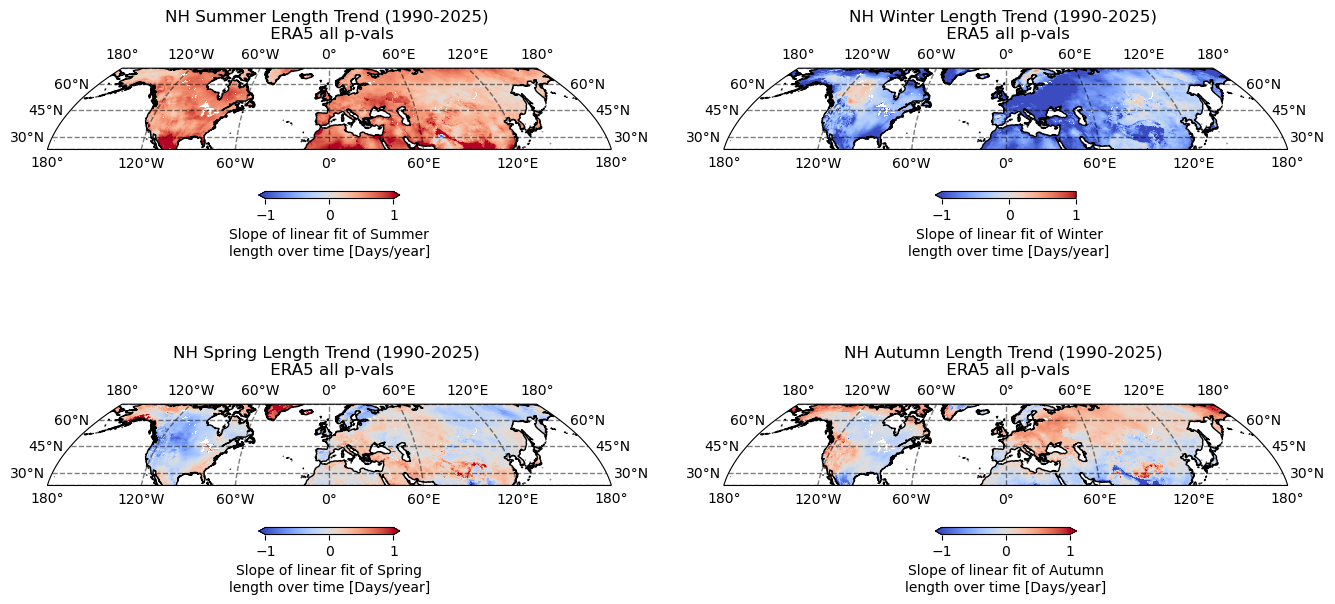

In [15]:
# Global summer length trend
fig = plt.figure(figsize=(16,8))

ax1 = fig.add_subplot(2,2,1, projection=ccrs.Robinson(central_longitude=0))
ax1.coastlines()
ax1.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5,  ylocs=mticker.FixedLocator([ 23.5,30,45,60, 70]), linestyle='--')
results_ds.sel(lat=slice(nh_min, nh_max)).SummerLengthSlope.plot(
    ax=ax1,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-1,
    vmax=1, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.25, 'location':'bottom'}
)
ax1.set_title("NH Summer Length Trend (1990-2025) \n ERA5 all p-vals")

ax2 = fig.add_subplot(2,2,2, projection=ccrs.Robinson(central_longitude=0))
ax2.coastlines()
ax2.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5,  ylocs=mticker.FixedLocator([ 23.5,30,45,60, 70]), linestyle='--')
results_ds.sel(lat=slice(nh_min, nh_max)).WinterLengthSlope.plot(
    ax=ax2,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-1,
    vmax=1, 
    cmap="coolwarm",#
    cbar_kwargs={'shrink': 0.25, 'location':'bottom'}
)
ax2.set_title("NH Winter Length Trend (1990-2025) \n ERA5 all p-vals")

ax3 = fig.add_subplot(2,2,3, projection=ccrs.Robinson(central_longitude=0))
ax3.coastlines()
ax3.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5,  ylocs=mticker.FixedLocator([ 23.5,30,45,60, 70]), linestyle='--')
results_ds.sel(lat=slice(nh_min, nh_max)).SpringLengthSlope.plot(
    ax=ax3,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-1,
    vmax=1, 
    cmap="coolwarm",#
    cbar_kwargs={'shrink': 0.25, 'location':'bottom'}
)
ax3.set_title("NH Spring Length Trend (1990-2025) \n ERA5 all p-vals")

ax4 = fig.add_subplot(2,2,4, projection=ccrs.Robinson(central_longitude=0))
ax4.coastlines()
ax4.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5,  ylocs=mticker.FixedLocator([ 23.5,30,45,60, 70]), linestyle='--')
results_ds.sel(lat=slice(nh_min, nh_max)).AutumnLengthSlope.plot(
    ax=ax4,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-1,
    vmax=1, 
    cmap="coolwarm",#
    cbar_kwargs={'shrink': 0.25, 'location':'bottom'}
)
ax4.set_title("NH Autumn Length Trend (1990-2025) \n ERA5 all p-vals")

#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.show()

### Apply FDR to p-values for each season

In [21]:
np.sum(results_ds.SummerLengthP.values <= 0), np.sum(results_ds.SummerLengthP.values == 0), np.sum(results_ds.SummerLengthP.values == 1)

(np.int64(0), np.int64(0), np.int64(0))

In [23]:
%%time

# use FDR correction func from scipi.stats
pval_fdr_cor_summ = stats.false_discovery_control(results_ds.SummerLengthP.values)
pval_fdr_cor_wint = stats.false_discovery_control(results_ds.WinterLengthP.values)
pval_fdr_cor_spr = stats.false_discovery_control(results_ds.SpringLengthP.values)
pval_fdr_cor_aut = stats.false_discovery_control(results_ds.AutumnLengthP.values)

# add as variable to dataset
results_ds['SummerLengthPvalFDR'] = (['lat','lon'], pval_fdr_cor_summ)
results_ds['WinterLengthPvalFDR'] = (['lat','lon'], pval_fdr_cor_wint)
results_ds['SpringLengthPvalFDR'] = (['lat','lon'], pval_fdr_cor_spr)
results_ds['AutumnLengthPvalFDR'] = (['lat','lon'], pval_fdr_cor_aut)

results_ds

CPU times: user 83.9 ms, sys: 46.2 ms, total: 130 ms
Wall time: 323 ms


<xarray.Dataset> Size: 72MB
Dimensions:              (lat: 521, lon: 1440)
Coordinates:
  * lat                  (lat) float64 4kB -60.0 -59.75 -59.5 ... 69.75 70.0
  * lon                  (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.5 179.8
Data variables:
    SummerLengthSlope    (lat, lon) float64 6MB ...
    SummerLengthP        (lat, lon) float64 6MB 0.999 0.999 ... 0.999 0.999
    WinterLengthSlope    (lat, lon) float64 6MB ...
    WinterLengthP        (lat, lon) float64 6MB 0.999 0.999 ... 0.999 0.999
    SpringLengthSlope    (lat, lon) float64 6MB ...
    SpringLengthP        (lat, lon) float64 6MB 0.999 0.999 ... 0.999 0.999
    AutumnLengthSlope    (lat, lon) float64 6MB ...
    AutumnLengthP        (lat, lon) float64 6MB 0.999 0.999 ... 0.999 0.999
    SummerLengthPvalFDR  (lat, lon) float64 6MB 0.999 0.999 ... 0.999 0.999
    WinterLengthPvalFDR  (lat, lon) float64 6MB 0.999 0.999 ... 0.999 0.999
    SpringLengthPvalFDR  (lat, lon) float64 6MB 0.999 0.999 ... 0.999 0.999
    AutumnLengthPvalFDR  (lat, lon) float64 6MB 0.999 0.999 ... 0.999 0.999

In [26]:
#!rm -r '../../../../Data/ERA5-global/Analysis/New-Fourier/Seasons/1990-2025_ALL_season_length_trends.nc'

### Write the length trend results out for later re-use

In [27]:
# write those results out for later use
output_path = '../../../../Data/ERA5-global/Analysis/New-Fourier/Seasons/1990-2025_ALL_season_length_trends.nc'
results_ds.to_netcdf(output_path)


## !!! CAN NOW START HERE

In [66]:
# read them back in, in case I am jumping to here in the script
input_path = '../../../../Data/ERA5-global/Analysis/New-Fourier/Seasons/1990-2025_ALL_season_length_trends.nc'
results_ds = xr.open_dataset(input_path)

In [67]:
results_ds

<xarray.Dataset> Size: 72MB
Dimensions:              (lat: 521, lon: 1440)
Coordinates:
  * lat                  (lat) float64 4kB -60.0 -59.75 -59.5 ... 69.75 70.0
  * lon                  (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.5 179.8
Data variables:
    SummerLengthSlope    (lat, lon) float64 6MB ...
    SummerLengthP        (lat, lon) float64 6MB ...
    WinterLengthSlope    (lat, lon) float64 6MB ...
    WinterLengthP        (lat, lon) float64 6MB ...
    SpringLengthSlope    (lat, lon) float64 6MB ...
    SpringLengthP        (lat, lon) float64 6MB ...
    AutumnLengthSlope    (lat, lon) float64 6MB ...
    AutumnLengthP        (lat, lon) float64 6MB ...
    SummerLengthPvalFDR  (lat, lon) float64 6MB ...
    WinterLengthPvalFDR  (lat, lon) float64 6MB ...
    SpringLengthPvalFDR  (lat, lon) float64 6MB ...
    AutumnLengthPvalFDR  (lat, lon) float64 6MB ...

In [68]:
results_ds.nbytes

72038728

#### relabel, adjust units for decades, and make better plot for publication?

In [69]:
# make a copy to keep original intact
res_plot = results_ds.copy(deep=True)

# update to be change in days per decade
res_plot['SummerLengthSlope'] = res_plot.SummerLengthSlope * 10
res_plot['WinterLengthSlope'] = res_plot.WinterLengthSlope * 10
res_plot['SpringLengthSlope'] = res_plot.SpringLengthSlope * 10
res_plot['AutumnLengthSlope'] = res_plot.AutumnLengthSlope * 10

# update attributes
res_plot['SummerLengthSlope'].attrs["long_name"] = "Change in Summer Length \n"
res_plot['SummerLengthSlope'].attrs["units"] = "days / decade"
res_plot['WinterLengthSlope'].attrs["long_name"] = "Change in Winter Length \n"
res_plot['WinterLengthSlope'].attrs["units"] = "days / decade"
res_plot['SpringLengthSlope'].attrs["long_name"] = "Change in Spring Length \n"
res_plot['SpringLengthSlope'].attrs["units"] = "days / decade"
res_plot['AutumnLengthSlope'].attrs["long_name"] = "Change in Autumn Length \n"
res_plot['AutumnLengthSlope'].attrs["units"] = "days / decade"

res_plot

<xarray.Dataset> Size: 72MB
Dimensions:              (lat: 521, lon: 1440)
Coordinates:
  * lat                  (lat) float64 4kB -60.0 -59.75 -59.5 ... 69.75 70.0
  * lon                  (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.5 179.8
Data variables:
    SummerLengthSlope    (lat, lon) float64 6MB nan nan nan nan ... nan nan nan
    SummerLengthP        (lat, lon) float64 6MB ...
    WinterLengthSlope    (lat, lon) float64 6MB nan nan nan nan ... nan nan nan
    WinterLengthP        (lat, lon) float64 6MB ...
    SpringLengthSlope    (lat, lon) float64 6MB nan nan nan nan ... nan nan nan
    SpringLengthP        (lat, lon) float64 6MB ...
    AutumnLengthSlope    (lat, lon) float64 6MB nan nan nan nan ... nan nan nan
    AutumnLengthP        (lat, lon) float64 6MB ...
    SummerLengthPvalFDR  (lat, lon) float64 6MB ...
    WinterLengthPvalFDR  (lat, lon) float64 6MB ...
    SpringLengthPvalFDR  (lat, lon) float64 6MB ...
    AutumnLengthPvalFDR  (lat, lon) float64 6MB ...

#### FDR applied - hatching for stat sig

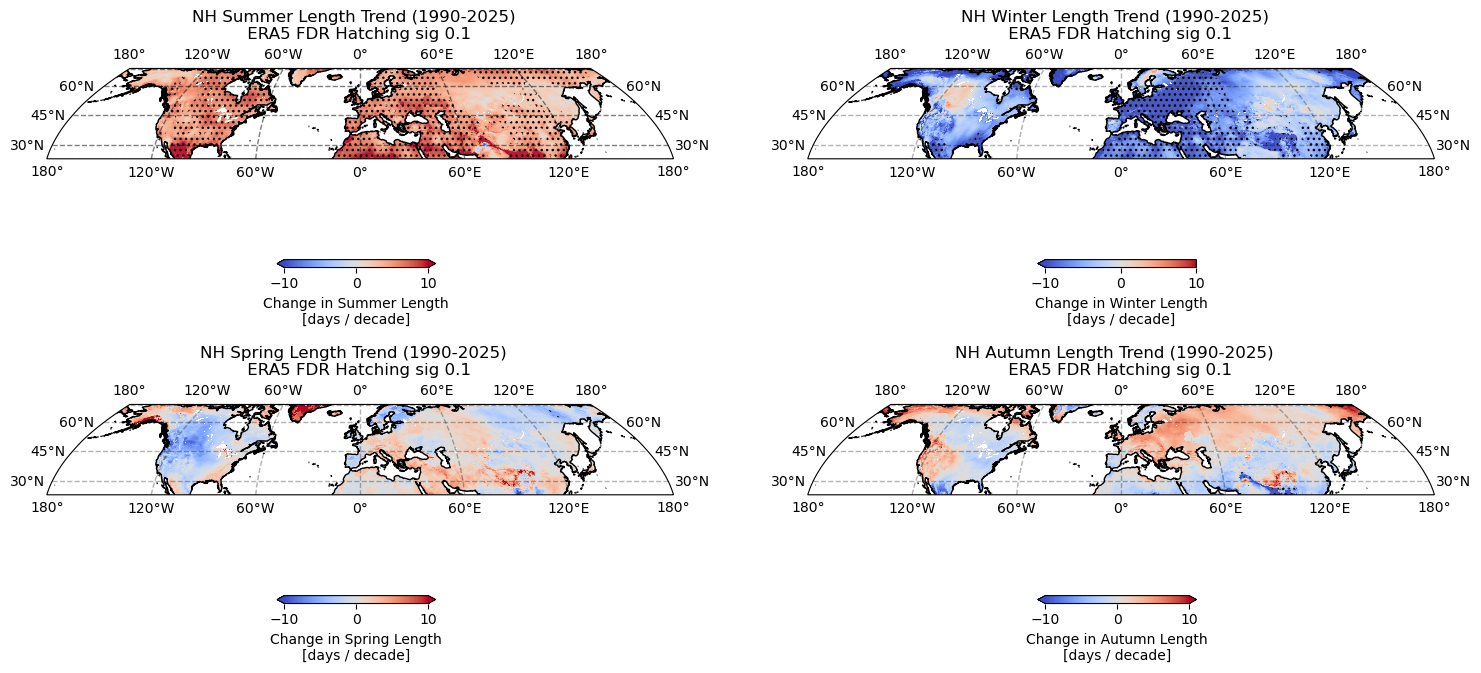

CPU times: user 2.11 s, sys: 125 ms, total: 2.24 s
Wall time: 2.25 s


In [78]:
%%time

# Global summer length trend
fig = plt.figure(figsize=(18,8))

# SUMMER
ax1 = fig.add_subplot(2,2,1, projection=ccrs.Robinson(central_longitude=0))
ax1.coastlines()
ax1.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5,  ylocs=mticker.FixedLocator([ 23.5,30,45,60, 70]), linestyle='--')
res_plot.sel(lat=slice(nh_min, nh_max)).SummerLengthSlope.plot(
    ax=ax1,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-10,
    vmax=10, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.25, 'location':'bottom'}
)
# mask for non sig at p > 0.1 via FDR
mksig = res_plot.where(np.isnan(res_plot.SummerLengthSlope.values) != True).SummerLengthPvalFDR.sel(lat=slice(nh_min, nh_max)) <= 0.1
mksig.where(mksig.values).plot.contourf(hatches=["..."], transform=ccrs.PlateCarree(),  
                                        cmap='coolwarm',alpha=0.1,
                                       cbar_kwargs={'shrink': 0.1, 'location':'bottom'})
fig.axes[-1].remove()
ax1.set_title("NH Summer Length Trend (1990-2025) \n ERA5 FDR Hatching sig 0.1")

# WINTER
ax2 = fig.add_subplot(2,2,2, projection=ccrs.Robinson(central_longitude=0))
ax2.coastlines()
ax2.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.3,  ylocs=mticker.FixedLocator([ 23.5,30,45,60, 70]), linestyle='--')
res_plot.sel(lat=slice(nh_min, nh_max)).WinterLengthSlope.plot(
    ax=ax2,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-10,
    vmax=10, 
    cmap="coolwarm",#
    cbar_kwargs={'shrink': 0.25, 'location':'bottom'}
)
# mask for non sig at p > 0.1 via FDR
mksig = res_plot.where(np.isnan(res_plot.WinterLengthSlope.values) != True).WinterLengthPvalFDR.sel(lat=slice(nh_min, nh_max)) <= 0.1
mksig.where(mksig.values).plot.contourf(hatches=["..."], transform=ccrs.PlateCarree(),  
                                        cmap='coolwarm',alpha=0.1,
                                       cbar_kwargs={'shrink': 0.1, 'location':'bottom'})
fig.axes[-1].remove()
ax2.set_title("NH Winter Length Trend (1990-2025) \n ERA5 FDR Hatching sig 0.1")

# SPRING
ax3 = fig.add_subplot(2,2,3, projection=ccrs.Robinson(central_longitude=0))
ax3.coastlines()
ax3.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.3,  ylocs=mticker.FixedLocator([ 23.5,30,45,60, 70]), linestyle='--')
res_plot.sel(lat=slice(nh_min, nh_max)).SpringLengthSlope.plot(
    ax=ax3,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-10,
    vmax=10, 
    cmap="coolwarm",#
    cbar_kwargs={'shrink': 0.25, 'location':'bottom'}
)
# mask for non sig at p > 0.1 via FDR
mksig = res_plot.where(np.isnan(res_plot.SpringLengthSlope.values) != True).SpringLengthPvalFDR.sel(lat=slice(nh_min, nh_max)) <= 0.1
mksig.where(mksig.values).plot.contourf(hatches=["..."], transform=ccrs.PlateCarree(),  
                                        cmap='coolwarm',alpha=0.1,
                                       cbar_kwargs={'shrink': 0.1, 'location':'bottom'})
fig.axes[-1].remove()
ax3.set_title("NH Spring Length Trend (1990-2025) \n ERA5 FDR Hatching sig 0.1")

# AUTUMN
ax4 = fig.add_subplot(2,2,4, projection=ccrs.Robinson(central_longitude=0))
ax4.coastlines()
ax4.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.3,  ylocs=mticker.FixedLocator([ 23.5,30,45,60, 70]), linestyle='--')
res_plot.sel(lat=slice(nh_min, nh_max)).AutumnLengthSlope.plot(
    ax=ax4,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-10,
    vmax=10, 
    cmap="coolwarm",#
    cbar_kwargs={'shrink': 0.25, 'location':'bottom'}
)
# mask for non sig at p > 0.1 via FDR
mksig = res_plot.where(np.isnan(res_plot.AutumnLengthSlope.values) != True).AutumnLengthPvalFDR.sel(lat=slice(nh_min, nh_max)) <= 0.1
mksig.where(mksig.values).plot.contourf(hatches=["..."], transform=ccrs.PlateCarree(),  
                                        cmap='coolwarm',alpha=0.1,
                                       cbar_kwargs={'shrink': 0.1, 'location':'bottom'})
fig.axes[-1].remove()
ax4.set_title("NH Autumn Length Trend (1990-2025) \n ERA5 FDR Hatching sig 0.1")

#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.show()





# remove the colorbar from the contour
#fig.axes[-1].remove()


# plt.savefig("./Plots/1990-2023_SummerLength_Trends_NH_FDR-notsig.png",bbox_inches='tight')



#### No hatching

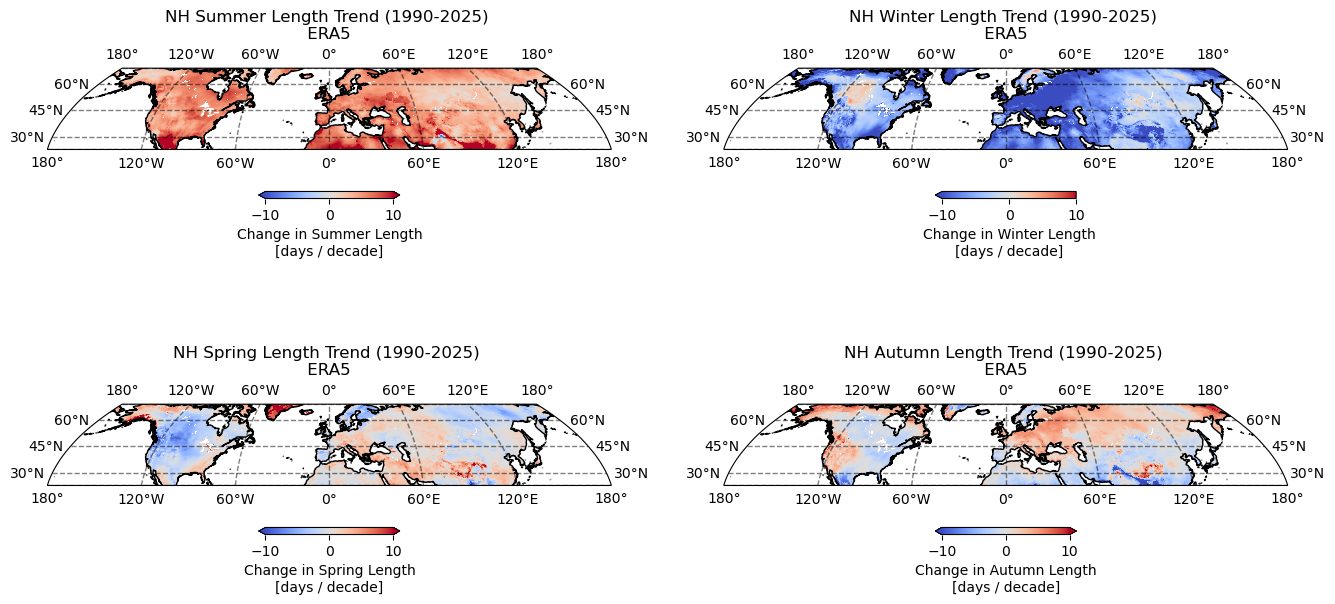

In [62]:
# Global summer length trend
fig = plt.figure(figsize=(16,8))

# SUMMER
ax1 = fig.add_subplot(2,2,1, projection=ccrs.Robinson(central_longitude=0))
ax1.coastlines()
ax1.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5,  ylocs=mticker.FixedLocator([ 23.5,30,45,60, 70]), linestyle='--')
res_plot.sel(lat=slice(nh_min, nh_max)).SummerLengthSlope.plot(
    ax=ax1,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-10,
    vmax=10, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.25, 'location':'bottom'}
)
# mask for non sig at p > 0.1 via FDR
ax1.set_title("NH Summer Length Trend (1990-2025) \n ERA5 ")

# WINTER
ax2 = fig.add_subplot(2,2,2, projection=ccrs.Robinson(central_longitude=0))
ax2.coastlines()
ax2.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5,  ylocs=mticker.FixedLocator([ 23.5,30,45,60, 70]), linestyle='--')
res_plot.sel(lat=slice(nh_min, nh_max)).WinterLengthSlope.plot(
    ax=ax2,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-10,
    vmax=10, 
    cmap="coolwarm",#
    cbar_kwargs={'shrink': 0.25, 'location':'bottom'}
)

ax2.set_title("NH Winter Length Trend (1990-2025) \n ERA5 ")

# SPRING
ax3 = fig.add_subplot(2,2,3, projection=ccrs.Robinson(central_longitude=0))
ax3.coastlines()
ax3.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5,  ylocs=mticker.FixedLocator([ 23.5,30,45,60, 70]), linestyle='--')
res_plot.sel(lat=slice(nh_min, nh_max)).SpringLengthSlope.plot(
    ax=ax3,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-10,
    vmax=10, 
    cmap="coolwarm",#
    cbar_kwargs={'shrink': 0.25, 'location':'bottom'}
)

ax3.set_title("NH Spring Length Trend (1990-2025) \n ERA5 ")

# AUTUMN
ax4 = fig.add_subplot(2,2,4, projection=ccrs.Robinson(central_longitude=0))
ax4.coastlines()
ax4.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5,  ylocs=mticker.FixedLocator([ 23.5,30,45,60, 70]), linestyle='--')
res_plot.sel(lat=slice(nh_min, nh_max)).AutumnLengthSlope.plot(
    ax=ax4,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-10,
    vmax=10, 
    cmap="coolwarm",#
    cbar_kwargs={'shrink': 0.25, 'location':'bottom'}
)

ax4.set_title("NH Autumn Length Trend (1990-2025) \n ERA5 ")

#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.show()


# plt.savefig("./Plots/1990-2023_SummerLength_Trends_NH_FDR-notsig.png",bbox_inches='tight')



# Load in Model Season Length Data

In [80]:
# models so far
models = ['ACCESS-ESM1-5',
    'BCC-CSM2-MR',
    'CMCC-ESM2',
    'FGOALS-g3',
    'GFDL-ESM4',
    'GISS-E2-1-G',
    'MIROC-ES2L',
    'MIROC6',
    'MPI-ESM1-2-HR',
    'MRI-ESM2-0',
    'NorESM2-LM']

## SSP2-4.5 NH Trends 2015 - 2099

In [81]:
%%time

# takes 25 min

# each model is roughly 5.6 GB but I drop 50% of the data by removing start/end values so total dataset is roughly 2.8 * 11 models

# open first model as base to merge with
# drop start/end vars

file_path2 = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+models[0]+'/regridded/Seasons/2015-2099_'+models[0]+'_ssp245_season_stats.nc'

# load and reduce dataset
nh_mod = xr.open_mfdataset(file_path2)
nh_mod = nh_mod.drop_vars(['WinterStart','WinterEnd','SummerStart','SummerEnd'])
nh_mod = nh_mod.sel(lat=slice(nh_min,nh_max))


for md in models[1:]:

    file_path2 = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/Seasons/2015-2099_'+md+'_ssp245_season_stats.nc'
    ds_i = xr.open_mfdataset(file_path2)
    ds_i = ds_i.drop_vars(['WinterStart','WinterEnd','SummerStart','SummerEnd'])
    ds_i = ds_i.sel(lat=slice(nh_min,nh_max))
    
    # merge together
    nh_mod = nh_mod.merge(ds_i)

# get multi-model mean per grid cell and replace nh_mod to save memory    
nh_mod = nh_mod.mean(dim=['experiment','model'])

nh_mod.load()

CPU times: user 2min 28s, sys: 4min 17s, total: 6min 46s
Wall time: 25min 7s


<xarray.Dataset> Size: 732MB
Dimensions:       (lat: 187, lon: 1440, time: 85, experiment: 1)
Coordinates:
  * lat           (lat) float64 1kB 23.5 23.75 24.0 24.25 ... 69.5 69.75 70.0
  * lon           (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
  * time          (time) datetime64[ns] 680B 2015-01-01 ... 2099-01-01
  * experiment    (experiment) <U6 24B 'ssp245'
Data variables:
    WinterLength  (experiment, time, lat, lon) float64 183MB nan nan ... nan nan
    SummerLength  (experiment, time, lat, lon) float64 183MB nan nan ... nan nan
    SpringLength  (experiment, time, lat, lon) float64 183MB nan nan ... nan nan
    AutumnLength  (experiment, time, lat, lon) float64 183MB nan nan ... nan nan

In [82]:
#nh_mod = nh_mod.mean(dim=['experiment'])

In [83]:
nh_mod

<xarray.Dataset> Size: 732MB
Dimensions:       (lat: 187, lon: 1440, time: 85)
Coordinates:
  * lat           (lat) float64 1kB 23.5 23.75 24.0 24.25 ... 69.5 69.75 70.0
  * lon           (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
  * time          (time) datetime64[ns] 680B 2015-01-01 ... 2099-01-01
Data variables:
    WinterLength  (time, lat, lon) float64 183MB nan nan nan nan ... nan nan nan
    SummerLength  (time, lat, lon) float64 183MB nan nan nan nan ... nan nan nan
    SpringLength  (time, lat, lon) float64 183MB nan nan nan nan ... nan nan nan
    AutumnLength  (time, lat, lon) float64 183MB nan nan nan nan ... nan nan nan

### Linear trends in season lengths for each grid cell 2015-2099

In [ ]:
%%time

# takes XX min for 85 years

# grid parameters for looping
num_lat = nh_mod.lat.shape[0]
num_lon = nh_mod.lon.shape[0]
loop_lats = nh_mod.lat.values[:num_lat]
loop_lons = nh_mod.lon.values[:num_lon]


# variables for OLS results, p-val needed for FDR adjustment
summerlength_slope = xr.DataArray(np.zeros((num_lat,num_lon)), 
                            coords=[loop_lats, loop_lons], 
                            dims=['lat','lon'])
summerlength_pval = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])
winterlength_slope = xr.DataArray(np.zeros((num_lat,num_lon)), 
                            coords=[loop_lats, loop_lons], 
                            dims=['lat','lon'])
winterlength_pval = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])
springlength_slope = xr.DataArray(np.zeros((num_lat,num_lon)), 
                            coords=[loop_lats, loop_lons], 
                            dims=['lat','lon'])
springlength_pval = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])
autumnlength_slope = xr.DataArray(np.zeros((num_lat,num_lon)), 
                            coords=[loop_lats, loop_lons], 
                            dims=['lat','lon'])
autumnlength_pval = xr.DataArray(np.zeros((num_lat,num_lon)), 
                           coords=[loop_lats, loop_lons], 
                           dims=['lat','lon'])

# add attributes for each season fit
summerlength_slope.attrs["long_name"] = "Slope of linear fit of Summer length over time"
summerlength_slope.attrs["units"] = "Days/year"

summerlength_pval.attrs["long_name"] = "p-value of linear fit"
summerlength_pval.attrs["units"] = "None"

winterlength_slope.attrs["long_name"] = "Slope of linear fit of Winter length over time"
winterlength_slope.attrs["units"] = "Days/year"

winterlength_pval.attrs["long_name"] = "p-value of linear fit"
winterlength_pval.attrs["units"] = "None"

springlength_slope.attrs["long_name"] = "Slope of linear fit of Spring length over time"
springlength_slope.attrs["units"] = "Days/year"

springlength_pval.attrs["long_name"] = "p-value of linear fit"
springlength_pval.attrs["units"] = "None"

autumnlength_slope.attrs["long_name"] = "Slope of linear fit of Autumn length over time"
autumnlength_slope.attrs["units"] = "Days/year"

autumnlength_pval.attrs["long_name"] = "p-value of linear fit"
autumnlength_pval.attrs["units"] = "None"


# loop through all of the lat,lon of interest
for input_lat in loop_lats:
    for input_lon in loop_lons:

        # if first summer length is nan this cell is not on land and/or outside lat range of data so skip it and set slopes to nan and pvals to 0.999
        if(np.isnan(nh_mod.SummerLength.sel(lat=input_lat, lon=input_lon).values[0])):
            summerlength_slope.loc[input_lat, input_lon], winterlength_slope.loc[input_lat, input_lon], springlength_slope.loc[input_lat, input_lon], autumnlength_slope.loc[input_lat, input_lon] = np.nan, np.nan, np.nan, np.nan 
            summerlength_pval.loc[input_lat, input_lon], winterlength_pval.loc[input_lat, input_lon], springlength_pval.loc[input_lat, input_lon], autumnlength_pval.loc[input_lat, input_lon] = 0.999, 0.999, 0.999, 0.999

        else:
            # *** SUMMER ***
            # create x & y values for linear fit
            x = nh_mod.time.dt.year.values
            y = nh_mod.SummerLength.sel(lat=input_lat, lon=input_lon).values
    
            # OLS fit 
            x = sm.add_constant(x)
            model = sm.OLS(y, x).fit()
    
            # load up data arrays with fit values
            summerlength_slope.loc[input_lat, input_lon] = model.params[1]
            
            # deal with any grid cells that return nan or zero for Pvalue because FDR function requires between 0 and 1
            if np.isnan(model.pvalues[1]):
                summerlength_pval.loc[input_lat, input_lon] = 0.999
            elif (model.pvalues[1] == 0):
                summerlength_pval.loc[input_lat, input_lon] = 1e-10
            else:
                # otherwise fit pvalue is OK
                summerlength_pval.loc[input_lat, input_lon] = model.pvalues[1]

            # *** WINTER ***
            # create x & y values
            x = nh_mod.time.dt.year.values
            y = nh_mod.WinterLength.sel(lat=input_lat, lon=input_lon).values
    
            # OLS fit 
            x = sm.add_constant(x)
            model = sm.OLS(y, x).fit()
    
            # load up data arrays with fit values
            winterlength_slope.loc[input_lat, input_lon] = model.params[1]
            
            # deal with few grid cells that return nan or zero for Pvalue because FDR function needs between 0 and 1
            if np.isnan(model.pvalues[1]):
                winterlength_pval.loc[input_lat, input_lon] = 0.999
            elif (model.pvalues[1] == 0):
                winterlength_pval.loc[input_lat, input_lon] = 1e-10
            else:
                # otherwise fit pvalue is OK
                winterlength_pval.loc[input_lat, input_lon] = model.pvalues[1]

            # *** SPRING ***
            # create x & y values
            x = nh_mod.time.dt.year.values
            y = nh_mod.SpringLength.sel(lat=input_lat, lon=input_lon).values
    
            # OLS fit 
            x = sm.add_constant(x)
            model = sm.OLS(y, x).fit()
    
            # load up data arrays with fit values
            springlength_slope.loc[input_lat, input_lon] = model.params[1]
            
            # deal with few grid cells that return nan or zero for Pvalue because FDR function needs between 0 and 1
            if np.isnan(model.pvalues[1]):
                springlength_pval.loc[input_lat, input_lon] = 0.999
            elif (model.pvalues[1] == 0):
                springlength_pval.loc[input_lat, input_lon] = 1e-10
            else:
                # otherwise fit pvalue is OK
                springlength_pval.loc[input_lat, input_lon] = model.pvalues[1]

            # *** AUTUMN ***
            # create x & y values
            x = nh_mod.time.dt.year.values
            y = nh_mod.AutumnLength.sel(lat=input_lat, lon=input_lon).values
    
            # OLS fit 
            x = sm.add_constant(x)
            model = sm.OLS(y, x).fit()
    
            # load up data arrays with fit values
            autumnlength_slope.loc[input_lat, input_lon] = model.params[1]
            
            # deal with few grid cells that return nan or zero for Pvalue because FDR function needs between 0 and 1
            if np.isnan(model.pvalues[1]):
                autumnlength_pval.loc[input_lat, input_lon] = 0.999
            elif (model.pvalues[1] == 0):
                autumnlength_pval.loc[input_lat, input_lon] = 1e-10
            else:
                # otherwise fit pvalue is OK
                autumnlength_pval.loc[input_lat, input_lon] = model.pvalues[1]

# results dataset
results_mod_ds = xr.Dataset(data_vars={'SummerLengthSlope':summerlength_slope,
                                   'SummerLengthP':summerlength_pval,
                                   'WinterLengthSlope':winterlength_slope,
                                   'WinterLengthP':winterlength_pval,
                                   'SpringLengthSlope':springlength_slope,
                                   'SpringLengthP':springlength_pval,
                                   'AutumnLengthSlope':autumnlength_slope,
                                   'AutumnLengthP':autumnlength_pval
                                  })

# see results
results_mod_ds

### A few quick maps to make sure it worked!

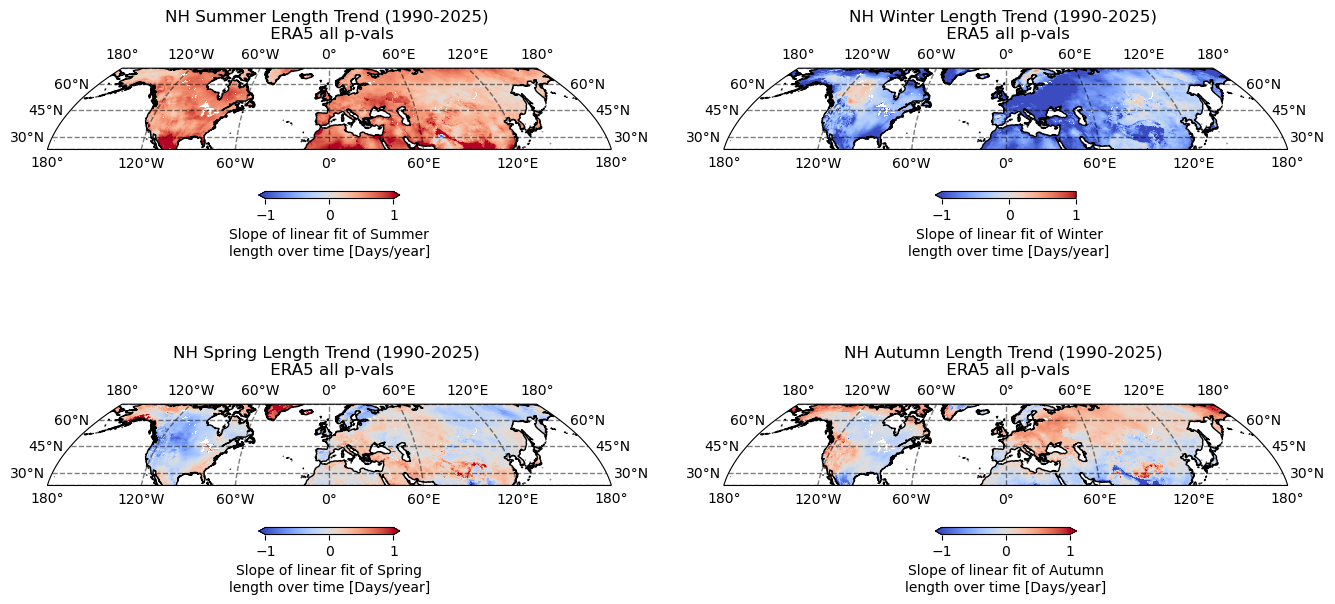

In [15]:
# Global summer length trend
fig = plt.figure(figsize=(16,8))

ax1 = fig.add_subplot(2,2,1, projection=ccrs.Robinson(central_longitude=0))
ax1.coastlines()
ax1.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5,  ylocs=mticker.FixedLocator([ 23.5,30,45,60, 70]), linestyle='--')
results_mod_ds.sel(lat=slice(nh_min, nh_max)).SummerLengthSlope.plot(
    ax=ax1,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-1,
    vmax=1, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.25, 'location':'bottom'}
)
ax1.set_title("NH Summer Length Trend (2015-2099) \n SSP245 all p-vals")

ax2 = fig.add_subplot(2,2,2, projection=ccrs.Robinson(central_longitude=0))
ax2.coastlines()
ax2.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5,  ylocs=mticker.FixedLocator([ 23.5,30,45,60, 70]), linestyle='--')
results_mod_ds.sel(lat=slice(nh_min, nh_max)).WinterLengthSlope.plot(
    ax=ax2,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-1,
    vmax=1, 
    cmap="coolwarm",#
    cbar_kwargs={'shrink': 0.25, 'location':'bottom'}
)
ax2.set_title("NH Winter Length Trend (2015-2099) \n SSP245 all p-vals")

ax3 = fig.add_subplot(2,2,3, projection=ccrs.Robinson(central_longitude=0))
ax3.coastlines()
ax3.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5,  ylocs=mticker.FixedLocator([ 23.5,30,45,60, 70]), linestyle='--')
results_mod_ds.sel(lat=slice(nh_min, nh_max)).SpringLengthSlope.plot(
    ax=ax3,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-1,
    vmax=1, 
    cmap="coolwarm",#
    cbar_kwargs={'shrink': 0.25, 'location':'bottom'}
)
ax3.set_title("NH Spring Length Trend (2015-2099) \n SSP245 all p-vals")

ax4 = fig.add_subplot(2,2,4, projection=ccrs.Robinson(central_longitude=0))
ax4.coastlines()
ax4.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5,  ylocs=mticker.FixedLocator([ 23.5,30,45,60, 70]), linestyle='--')
results_mod_ds.sel(lat=slice(nh_min, nh_max)).AutumnLengthSlope.plot(
    ax=ax4,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-1,
    vmax=1, 
    cmap="coolwarm",#
    cbar_kwargs={'shrink': 0.25, 'location':'bottom'}
)
ax4.set_title("NH Autumn Length Trend (2015-2099) \n SSP245 all p-vals")

#plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
plt.show()

### Apply FDR to p-values for each season

In [21]:
np.sum(results_mod_ds.SummerLengthP.values <= 0), np.sum(results_mod_ds.SummerLengthP.values == 0), np.sum(results_mod_ds.SummerLengthP.values == 1)

(np.int64(0), np.int64(0), np.int64(0))

In [23]:
%%time

# use FDR correction func from scipi.stats
pval_fdr_cor_summ = stats.false_discovery_control(results_mod_ds.SummerLengthP.values)
pval_fdr_cor_wint = stats.false_discovery_control(results_mod_ds.WinterLengthP.values)
pval_fdr_cor_spr = stats.false_discovery_control(results_mod_ds.SpringLengthP.values)
pval_fdr_cor_aut = stats.false_discovery_control(results_mod_ds.AutumnLengthP.values)

# add as variable to dataset
results_mod_ds['SummerLengthPvalFDR'] = (['lat','lon'], pval_fdr_cor_summ)
results_mod_ds['WinterLengthPvalFDR'] = (['lat','lon'], pval_fdr_cor_wint)
results_mod_ds['SpringLengthPvalFDR'] = (['lat','lon'], pval_fdr_cor_spr)
results_mod_ds['AutumnLengthPvalFDR'] = (['lat','lon'], pval_fdr_cor_aut)

results_mod_ds

CPU times: user 83.9 ms, sys: 46.2 ms, total: 130 ms
Wall time: 323 ms


<xarray.Dataset> Size: 72MB
Dimensions:              (lat: 521, lon: 1440)
Coordinates:
  * lat                  (lat) float64 4kB -60.0 -59.75 -59.5 ... 69.75 70.0
  * lon                  (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.5 179.8
Data variables:
    SummerLengthSlope    (lat, lon) float64 6MB ...
    SummerLengthP        (lat, lon) float64 6MB 0.999 0.999 ... 0.999 0.999
    WinterLengthSlope    (lat, lon) float64 6MB ...
    WinterLengthP        (lat, lon) float64 6MB 0.999 0.999 ... 0.999 0.999
    SpringLengthSlope    (lat, lon) float64 6MB ...
    SpringLengthP        (lat, lon) float64 6MB 0.999 0.999 ... 0.999 0.999
    AutumnLengthSlope    (lat, lon) float64 6MB ...
    AutumnLengthP        (lat, lon) float64 6MB 0.999 0.999 ... 0.999 0.999
    SummerLengthPvalFDR  (lat, lon) float64 6MB 0.999 0.999 ... 0.999 0.999
    WinterLengthPvalFDR  (lat, lon) float64 6MB 0.999 0.999 ... 0.999 0.999
    SpringLengthPvalFDR  (lat, lon) float64 6MB 0.999 0.999 ... 0.999 0.999
    AutumnLengthPvalFDR  (lat, lon) float64 6MB 0.999 0.999 ... 0.999 0.999

In [26]:
#!rm -r '../../../../Data/ERA5-global/Analysis/New-Fourier/Seasons/1990-2025_ALL_season_length_trends.nc'

### Write the length trend results out for later re-use

In [27]:
# write those results out for later use
output_path = '../../../../Data/     Seasons/2015-2099_ssp245_ALL_season_length_trends.nc'
results_mod_ds.to_netcdf(output_path)


# ******* BELOW NOT UPDATED

### North America MK test only

In [29]:

# central_longitude = -(91 + 52 / 60)
# central_latitude = 40

# ############
# #Global map of summer length
# fig = plt.figure(figsize=(15,9))

# # assign axis and def projection to use
# ax = plt.axes(projection=ccrs.LambertConformal(central_longitude=central_longitude, central_latitude=central_latitude))

# # add coastlines and grid
# ax.coastlines()
# ax.gridlines(draw_labels=True, linewidth=1, color='black', alpha=0.5, linestyle='--')

# dataplot = results_ds_an.LengthMKSlope.where((((ds_length_analysis.lat >= 23.5) & (ds_length_analysis.lat <= 70)) | 
#                               ((ds_length_analysis.lat <= -23.5) & (ds_length_analysis.lat >= -70)))).plot(
#     ax=ax,
#     transform=ccrs.PlateCarree(), # assign map projection
#     vmin=-1.0,
#     vmax=1.0, 
#     cmap="coolwarm",
#     cbar_kwargs={'shrink': 0.5}
    
# )

# # points with MK test p-value under 0.05
# mksig = results_ds_an.LengthMKP.where((((ds_length_analysis.lat >= 23.5) & (ds_length_analysis.lat <= 70)) | 
#                               ((ds_length_analysis.lat <= -23.5) & (ds_length_analysis.lat >= -70)))) <= 0.1

# mksig.where(mksig.values).plot.contourf(hatches=".", transform=ccrs.PlateCarree(), 
#                                         #colors='none', 
#                                         cmap='none' )#cbar_kwargs={'shrink': 0.0})

# # remove the colorbar from the contour
# fig.axes[-1].remove()



# ax.set_extent((-130, -60, 20, 75))

# provinces_50m = cfeature.NaturalEarthFeature('cultural',
#                                              'admin_1_states_provinces_lines',
#                                              '50m',
#                                              facecolor='none')
# ax.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor='black')
# ax.add_feature(cfeature.STATES, linewidth=0.3, edgecolor='brown')
# ax.add_feature(provinces_50m)
# plt.title("Summer Length Trend (1990-2023) \n w/ Hatches for MK test sig (Fourier)")#+" using 1961-1990 baseline")
# #plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
# plt.tight_layout()
# #plt.savefig("./Plots/"+str(input_year)+"_SummerLength_global.png")
# plt.show()


#### Europe with MK stat sig

In [30]:
# central_longitude = 0
# central_latitude = 40

# ############
# #Global map of summer length
# fig = plt.figure(figsize=(15,9))

# # assign axis and def projection to use
# ax = plt.axes(projection=ccrs.LambertConformal(central_longitude=central_longitude, central_latitude=central_latitude))

# # add coastlines and grid
# ax.coastlines()
# ax.gridlines(draw_labels=True, linewidth=1, color='black', alpha=0.5, linestyle='--')

# dataplot = results_ds_an.LengthMKSlope.where((((ds_length_analysis.lat >= 23.5) & (ds_length_analysis.lat <= 70)) | 
#                               ((ds_length_analysis.lat <= -23.5) & (ds_length_analysis.lat >= -70)))).plot(
#     ax=ax,
#     transform=ccrs.PlateCarree(), # assign map projection
#     vmin=-1,
#     vmax=1, 
#     cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
#     cbar_kwargs={'shrink': 0.5}
    
# )

# # points with MK test p-value under 0.05
# mksig = results_ds_an.LengthMKP.where((((ds_length_analysis.lat >= 23.5) & (ds_length_analysis.lat <= 70)) | 
#                               ((ds_length_analysis.lat <= -23.5) & (ds_length_analysis.lat >= -70)))) <= 0.05

# mksig.where(mksig.values).plot.contourf(hatches=".", transform=ccrs.PlateCarree(), 
#                                         #colors='none', 
#                                         cmap='none' )#cbar_kwargs={'shrink': 0.0})

# # remove the colorbar from the contour
# fig.axes[-1].remove()

# ax.set_extent((-30, 60, 20, 75))

# provinces_50m = cfeature.NaturalEarthFeature('cultural',
#                                              'admin_1_states_provinces_lines',
#                                              '50m',
#                                              facecolor='none')
# ax.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor='black')
# ax.add_feature(cfeature.STATES, linewidth=0.3, edgecolor='brown')
# ax.add_feature(provinces_50m)

# plt.title("Summer Length Trend (1990-2023) \n w/ Hatches for MK test sig (Fourier)")#+" using 1961-1990 baseline")
# #plt.savefig("./Plots/"+str(input_year)+"_SummerMeanHS_global.png")
# plt.tight_layout()
# plt.show()




In [50]:
results_ds_an

<xarray.Dataset> Size: 25MB
Dimensions:        (lat: 721, lon: 1440)
Coordinates:
  * lat            (lat) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * lon            (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    LengthMKSlope  (lat, lon) float64 8MB 0.03125 0.03125 ... 0.1724 0.1724
    LengthMKH      (lat, lon) float64 8MB 0.0 0.0 0.0 0.0 ... 1.0 1.0 1.0 1.0
    LengthMKP      (lat, lon) float64 8MB 0.4964 0.4964 ... 0.02122 0.02122

### SH only map

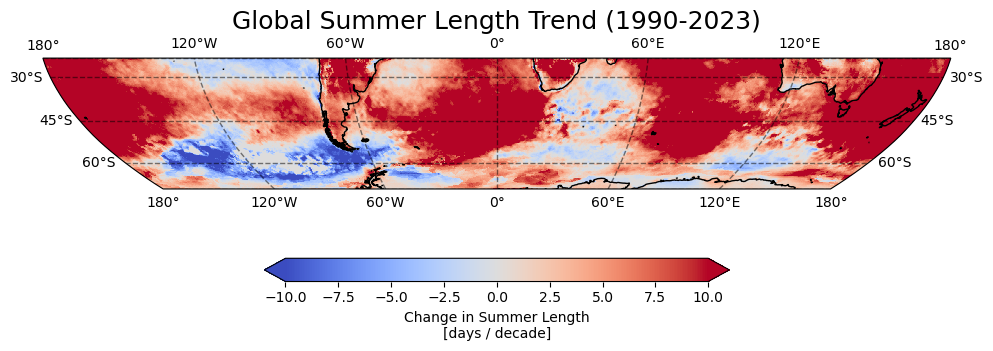

In [5]:
sh_min = -70
sh_max = -23.5

# Global summer length trend
fig = plt.figure(figsize=(12,6))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5, ylocs=mticker.FixedLocator([ -70,-60,-45,-30, -23.5]), linestyle='--')

res_plot.LengthMKSlope.sel(lat=slice(sh_min, sh_max)).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-10,
    vmax=10, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5, 'location':'bottom'}
)

plt.title("Global Summer Length Trend (1990-2023)", fontsize=18)#+" using 1961-1990 baseline")
plt.savefig("./Plots/1990-2023_SummerLength_Trends_SH.png",bbox_inches='tight')
plt.savefig("./Plots/1990-2023_SummerLength_Trends_SH.pdf",bbox_inches='tight')
plt.show()

#### FDR not sig

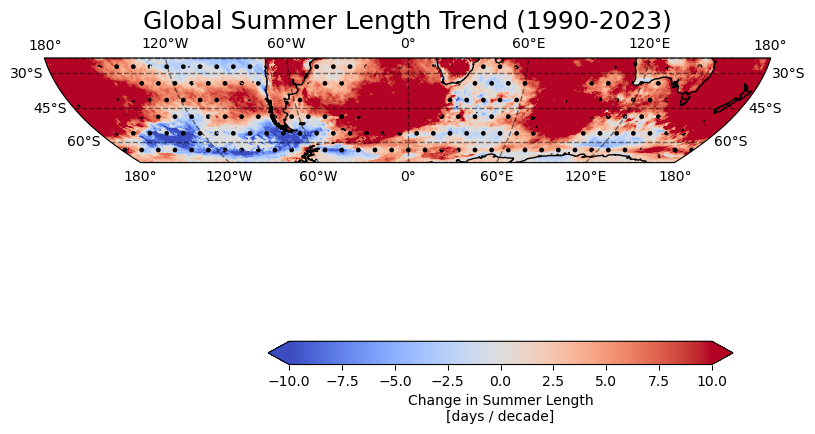

In [31]:
sh_min = -70
sh_max = -23.5

# Global summer length trend
fig = plt.figure(figsize=(12,6))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5, ylocs=mticker.FixedLocator([ -70,-60,-45,-30, -23.5]), linestyle='--')

res_plot.LengthMKSlope.sel(lat=slice(sh_min, sh_max)).plot(#where(results_ds_an_p.LengthPvalFDR <= 0.1).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-10,
    vmax=10, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5, 'location':'bottom'}
)

# points with MK test p-value under 0.05
mksig = results_ds_an_p.LengthPvalFDR.sel(lat=slice(sh_min, sh_max)) > 0.1

mksig.where(mksig.values).plot.contourf(hatches=".", transform=ccrs.PlateCarree(), 
                                        #colors='none', 
                                        cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()

plt.title("Global Summer Length Trend (1990-2023)", fontsize=18)#+" using 1961-1990 baseline")
plt.savefig("./Plots/1990-2023_SummerLength_Trends_SH_FDR-notsig.png",bbox_inches='tight')
plt.savefig("./Plots/1990-2023_SummerLength_Trends_SH_FDR-notsig.pdf",bbox_inches='tight')
plt.show()

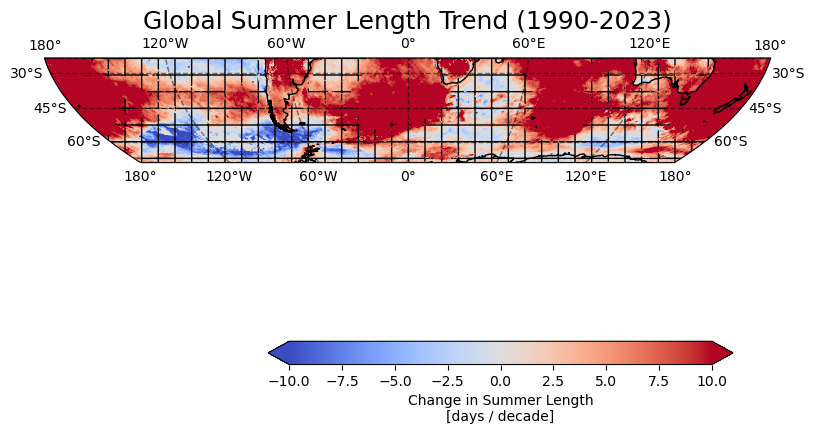

In [172]:
sh_min = -70
sh_max = -23.5

# Global summer length trend
fig = plt.figure(figsize=(12,6))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5, ylocs=mticker.FixedLocator([ -70,-60,-45,-30, -23.5]), linestyle='--')

res_plot.LengthMKSlope.sel(lat=slice(sh_min, sh_max)).plot(#where(results_ds_an_p.LengthPvalFDR <= 0.1).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-10,
    vmax=10, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5, 'location':'bottom'}
)

# points with MK test p-value under 0.05
mksig = results_ds_an_p.LengthPvalFDR.sel(lat=slice(sh_min, sh_max)) > 0.1

mksig.where(mksig.values).plot.contourf(hatches="+", transform=ccrs.PlateCarree(), 
                                        #colors='none', 
                                        cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()

plt.title("Global Summer Length Trend (1990-2023)", fontsize=18)#+" using 1961-1990 baseline")
plt.savefig("./Plots/1990-2023_SummerLength_Trends_SH_FDR-notsig+.png",bbox_inches='tight')
plt.savefig("./Plots/1990-2023_SummerLength_Trends_SH_FDR-notsig+.pdf",bbox_inches='tight')
plt.show()

#### FDR YES sig

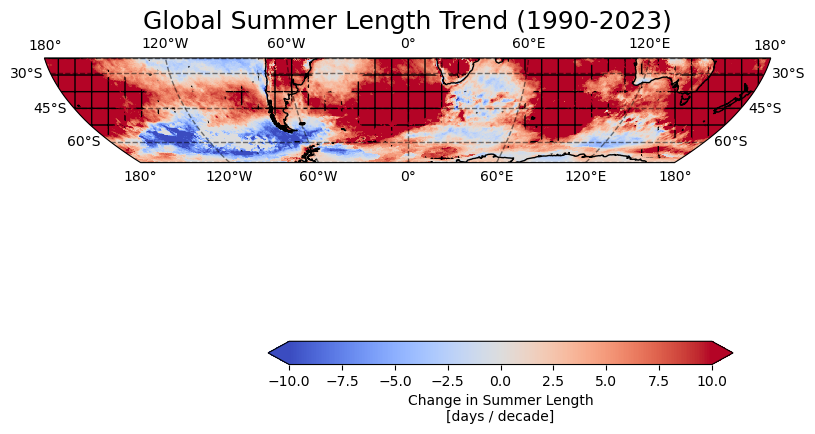

In [32]:
sh_min = -70
sh_max = -23.5

# Global summer length trend
fig = plt.figure(figsize=(12,6))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5, ylocs=mticker.FixedLocator([ -70,-60,-45,-30, -23.5]), linestyle='--')

res_plot.LengthMKSlope.sel(lat=slice(sh_min, sh_max)).plot(#where(results_ds_an_p.LengthPvalFDR <= 0.1).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-10,
    vmax=10, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5, 'location':'bottom'}
)

# mask for non sig at p > 0.1 via FDR
mksig = results_ds_an_p.LengthPvalFDR.sel(lat=slice(sh_min, sh_max)) <= 0.1

mksig.where(mksig.values).plot.contourf(hatches="+", transform=ccrs.PlateCarree(), 
                                        #colors='none', 
                                        cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()

plt.title("Global Summer Length Trend (1990-2023)", fontsize=18)#+" using 1961-1990 baseline")
plt.savefig("./Plots/1990-2023_SummerLength_Trends_SH_FDR-sig+.png",bbox_inches='tight')
plt.savefig("./Plots/1990-2023_SummerLength_Trends_SH_FDR-sig+.pdf",bbox_inches='tight')
plt.show()

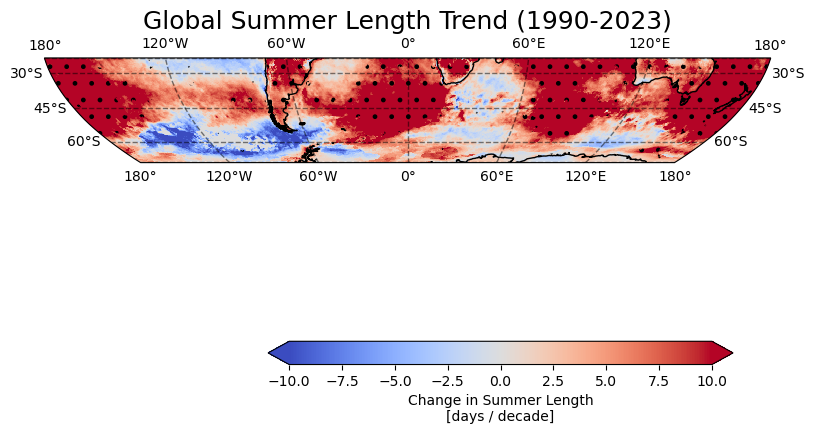

In [33]:
sh_min = -70
sh_max = -23.5

# Global summer length trend
fig = plt.figure(figsize=(12,6))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5, ylocs=mticker.FixedLocator([ -70,-60,-45,-30, -23.5]), linestyle='--')

res_plot.LengthMKSlope.sel(lat=slice(sh_min, sh_max)).plot(#where(results_ds_an_p.LengthPvalFDR <= 0.1).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-10,
    vmax=10, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5, 'location':'bottom'}
)

# mask for non sig at p > 0.1 via FDR
mksig = results_ds_an_p.LengthPvalFDR.sel(lat=slice(sh_min, sh_max)) <= 0.1

mksig.where(mksig.values).plot.contourf(hatches="..", transform=ccrs.PlateCarree(), 
                                        #colors='none', 
                                        cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()

plt.title("Global Summer Length Trend (1990-2023)", fontsize=18)#+" using 1961-1990 baseline")
plt.savefig("./Plots/1990-2023_SummerLength_Trends_SH_FDR-sigdot.png",bbox_inches='tight')
plt.savefig("./Plots/1990-2023_SummerLength_Trends_SH_FDR-sigdot.pdf",bbox_inches='tight')
plt.show()

#### OLS (MK) Sig

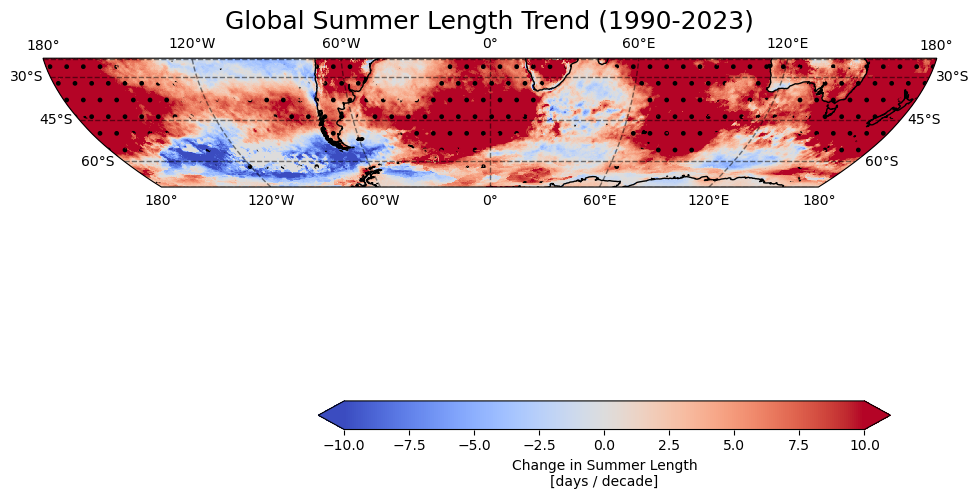

In [35]:
# Global summer length trend
fig = plt.figure(figsize=(12,6))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5, ylocs=mticker.FixedLocator([ -70,-60,-45,-30, -23.5]), linestyle='--')

res_plot.LengthMKSlope.sel(lat=slice(sh_min, sh_max)).plot(#where(results_ds_an_p.LengthPvalFDR <= 0.1).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-10,
    vmax=10, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5, 'location':'bottom'}
)

# points with MK test p-value under 0.1
mksig = results_ds_an.LengthMKP.sel(lat=slice(sh_min, sh_max)) <= 0.1

mksig.where(mksig.values).plot.contourf(hatches=".", transform=ccrs.PlateCarree(), 
                                        #colors='none', 
                                        cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()

plt.title("Global Summer Length Trend (1990-2023)", fontsize=18)#+" using 1961-1990 baseline")
plt.savefig("./Plots/1990-2023_SummerLength_Trends_SH_OLS-sig.png",bbox_inches='tight')
plt.savefig("./Plots/1990-2023_SummerLength_Trends_SH_OLS-sig.pdf",bbox_inches='tight')

plt.tight_layout()
plt.show()

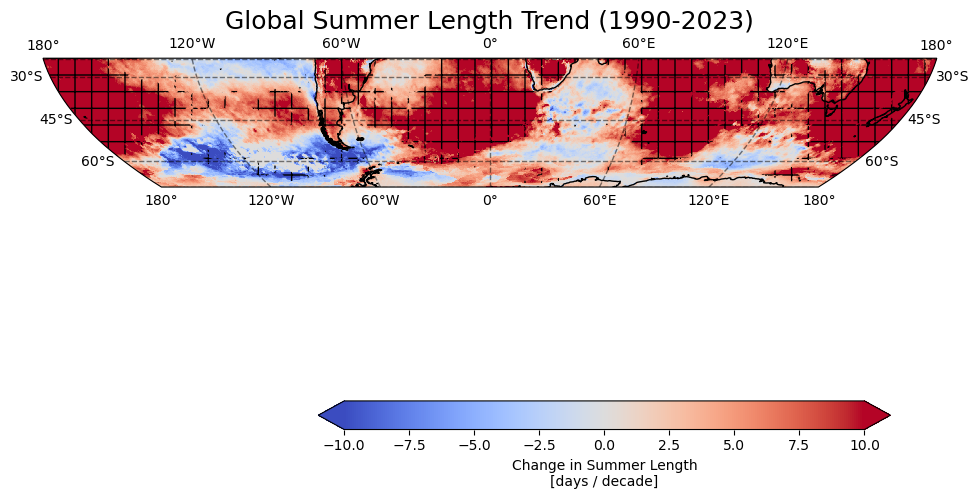

In [37]:
# Global summer length trend
fig = plt.figure(figsize=(12,6))

# assign axis and def projection to use
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# add coastlines and grid
ax.coastlines()
ax.gridlines(draw_labels=True,linewidth=1, color='black', alpha=0.5, ylocs=mticker.FixedLocator([ -70,-60,-45,-30, -23.5]), linestyle='--')

res_plot.LengthMKSlope.sel(lat=slice(sh_min, sh_max)).plot(#where(results_ds_an_p.LengthPvalFDR <= 0.1).plot(
    ax=ax,
    transform=ccrs.PlateCarree(), # assign map projection
    vmin=-10,
    vmax=10, 
    cmap="coolwarm",#"YlOrRd"#cmap="coolwarm"
    cbar_kwargs={'shrink': 0.5, 'location':'bottom'}
)

# points with MK test p-value under 0.1
mksig = results_ds_an.LengthMKP.sel(lat=slice(sh_min, sh_max)) <= 0.1

mksig.where(mksig.values).plot.contourf(hatches="+", transform=ccrs.PlateCarree(), 
                                        #colors='none', 
                                        cmap='none' )#cbar_kwargs={'shrink': 0.0})

# remove the colorbar from the contour
fig.axes[-1].remove()

plt.title("Global Summer Length Trend (1990-2023)", fontsize=18)#+" using 1961-1990 baseline")
plt.savefig("./Plots/1990-2023_SummerLength_Trends_SH_OLS-sig+.png",bbox_inches='tight')
plt.savefig("./Plots/1990-2023_SummerLength_Trends_SH_OLS-sig+.pdf",bbox_inches='tight')

plt.tight_layout()
plt.show()